# Early Stage Diabetes Risk Prediction

Predict whether a patient is likely to be diabetic from symptoms, age and gender.

- Dataset: [Early Stage Diabetes Risk Prediction (UCI)](https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset), CC BY 4.0, questionnaire data from Sylhet Diabetes Hospital, Bangladesh
- Put `diabetes_data_upload.csv` in a `data/` folder next to this notebook
- Model: Random Forest Classifier
- Exact duplicate records are removed before splitting, otherwise the same patient can sit in both train and test

This is a learning project. It is not a medical tool and must not be used to diagnose anyone.

In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data/diabetes_data_upload.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("diabetes_data_upload.csv")   # also works if the csv sits next to the notebook

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
df

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No,Positive
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No,Positive
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes,Positive
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No,Negative


In [2]:
# data understanding
print(f"Total Patients: {df.shape[0]}")
print(f"Total Medical Features: {df.shape[1]}\n")

Total Patients: 520
Total Medical Features: 17



In [3]:
df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-null    str  
 11  delayed healing     520 non-null    str  
 12  partial paresis     520 non-null    str  
 13  muscle stiffness    520 non-null    str  
 14  Alopecia            520 non-null    str  
 15  Obesity             520 non-null    str  
 16  class               520 non-null    str  
dtypes: int64

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [4]:
# data exporation
# Check every column for NaN (missing) values
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0]) 
if missing_data.sum() == 0:
    print("The dataset is perfectly clean. No missing values.")
else:
    print(" Missing values detected. You will need to clean these later.")
# age statistical spread
# Age is the only numerical column in this dataset, so we describe it separately
display(df['Age'].describe().round(1))

Series([], dtype: int64)
The dataset is perfectly clean. No missing values.


count    520.0
mean      48.0
std       12.2
min       16.0
25%       39.0
50%       47.5
75%       57.0
max       90.0
Name: Age, dtype: float64

In [5]:
# Calculate exact counts
target_counts = df['class'].value_counts()
print(target_counts)
# Calculate percentages
target_percentages = df['class'].value_counts(normalize=True) * 100
print("Percentages:")
print(target_percentages.round(2).astype(str) + '%')

class
Positive    320
Negative    200
Name: count, dtype: int64
Percentages:
class
Positive    61.54%
Negative    38.46%
Name: proportion, dtype: str


In [6]:
# Get all column names except 'Age' and 'class'
categorical_features = df.columns.drop(['Age', 'class'])
# Loop through each medical feature and print how many Yes/No or Male/Female answers exist
for feature in categorical_features:
    print(f"\n{feature.upper()}:")
    print(df[feature].value_counts())
    print("-" * 30)


GENDER:
Gender
Male      328
Female    192
Name: count, dtype: int64
------------------------------

POLYURIA:
Polyuria
No     262
Yes    258
Name: count, dtype: int64
------------------------------

POLYDIPSIA:
Polydipsia
No     287
Yes    233
Name: count, dtype: int64
------------------------------

SUDDEN WEIGHT LOSS:
sudden weight loss
No     303
Yes    217
Name: count, dtype: int64
------------------------------

WEAKNESS:
weakness
Yes    305
No     215
Name: count, dtype: int64
------------------------------

POLYPHAGIA:
Polyphagia
No     283
Yes    237
Name: count, dtype: int64
------------------------------

GENITAL THRUSH:
Genital thrush
No     404
Yes    116
Name: count, dtype: int64
------------------------------

VISUAL BLURRING:
visual blurring
No     287
Yes    233
Name: count, dtype: int64
------------------------------

ITCHING:
Itching
No     267
Yes    253
Name: count, dtype: int64
------------------------------

IRRITABILITY:
Irritability
No     394
Yes    126
Name:

In [7]:
# Duplicate records
# Exact duplicate rows are common in this dataset. If a row sits in both train and test,
# the model is "tested" on a patient it has already seen, and accuracy looks higher than it is.
n_dup = df_raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} out of {len(df_raw)}")

df_clean = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df_clean)}")
print("\nClass balance after cleaning:")
print(df_clean['class'].value_counts())

Exact duplicate rows: 269 out of 520
Rows after removing duplicates: 251

Class balance after cleaning:
class
Positive    173
Negative     78
Name: count, dtype: int64


In [8]:
# binary encoding
# Start from the de-duplicated data, so this cell is safe to re-run
df = df_clean.copy()
# Encode the Target Variable (Diabetes Risk)
df['class'] = df['class'].map({'Positive': 1, 'Negative': 0})
# Encode the Gender Column
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
# Encode all the Symptom Columns (Yes/No)
# We drop Age, Gender, and class because they are already handled
symptom_columns = df.columns.drop(['Age', 'Gender', 'class'])
for col in symptom_columns:
    df[col] = df[col].map({'Yes': 1, 'No': 0})
print("All text converted to numbers.")
# Prove it worked by displaying the new numeric blueprint
display(df.head())

All text converted to numbers.


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


Visualising top predictors


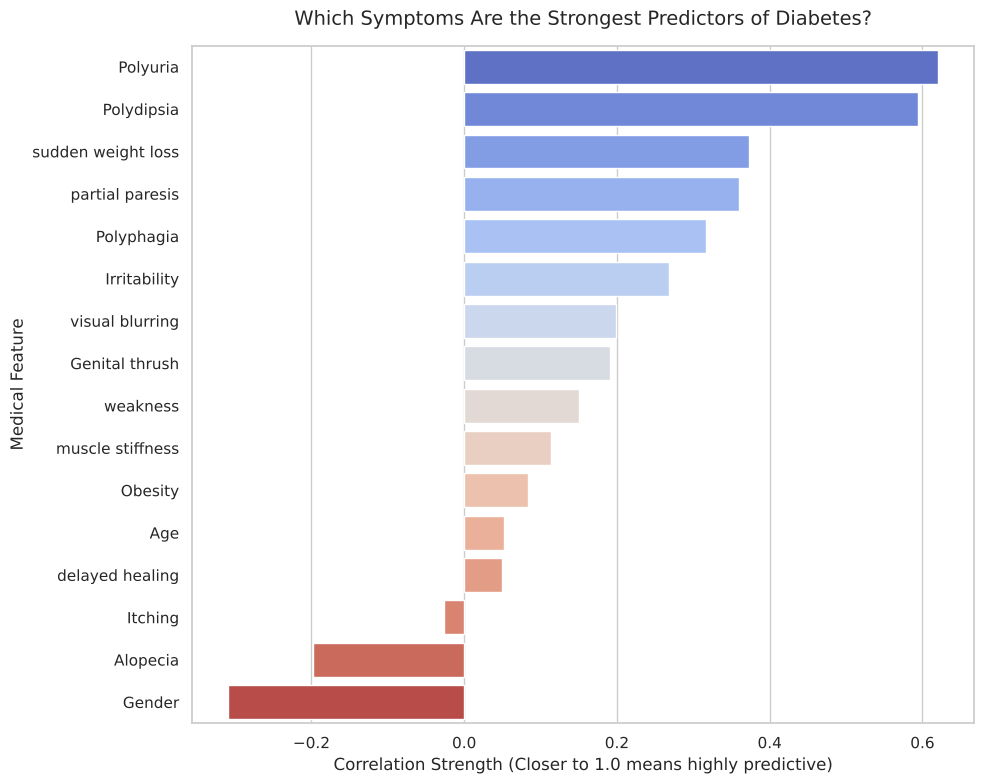

In [9]:
# data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Set professional theme
sns.set_theme(style="whitegrid")
print("Visualising top predictors")
plt.figure(figsize=(10, 8))
# Calculate correlation with 'class', drop the 'class' column itself, and sort
correlations = df.corr()['class'].drop('class').sort_values(ascending=False)
# Plot the correlations (warning-free with hue and legend=False)
sns.barplot(x=correlations.values, y=correlations.index, hue=correlations.index, palette='coolwarm', legend=False)

plt.title("Which Symptoms Are the Strongest Predictors of Diabetes?", fontsize=14, pad=15)
plt.xlabel("Correlation Strength (Closer to 1.0 means highly predictive)", fontsize=12)
plt.ylabel("Medical Feature", fontsize=12)
plt.tight_layout()
plt.show()

Visualizing age spread


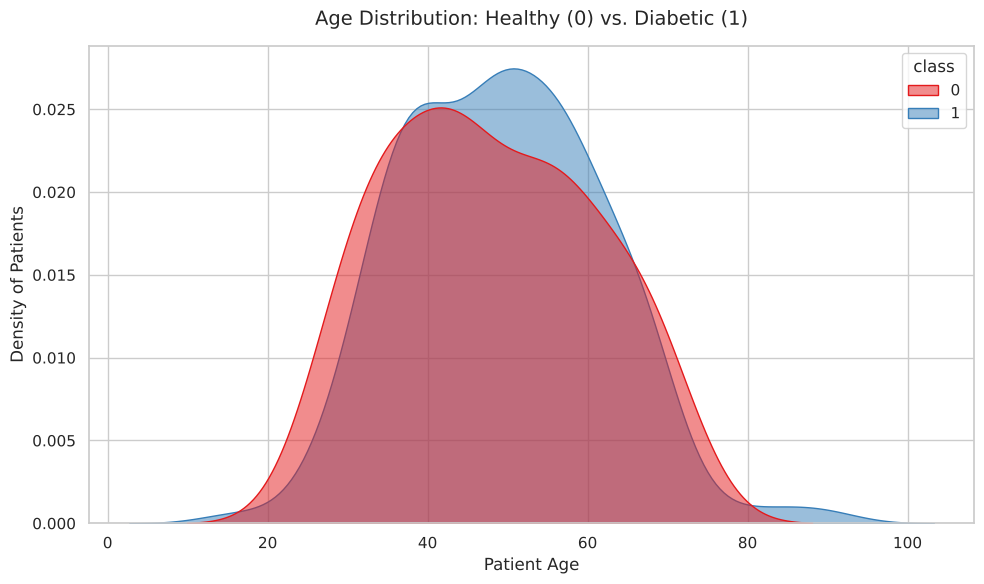

In [10]:
print("Visualizing age spread")
plt.figure(figsize=(10, 6))

# Plot the distribution of Age, colored by Diabetes Risk (class)
sns.kdeplot(data=df, x='Age', hue='class', fill=True, palette='Set1', common_norm=False, alpha=0.5)

plt.title("Age Distribution: Healthy (0) vs. Diabetic (1)", fontsize=14, pad=15)
plt.xlabel("Patient Age", fontsize=12)
plt.ylabel("Density of Patients", fontsize=12)

plt.tight_layout()
plt.show()

Visualizing gender and obesity


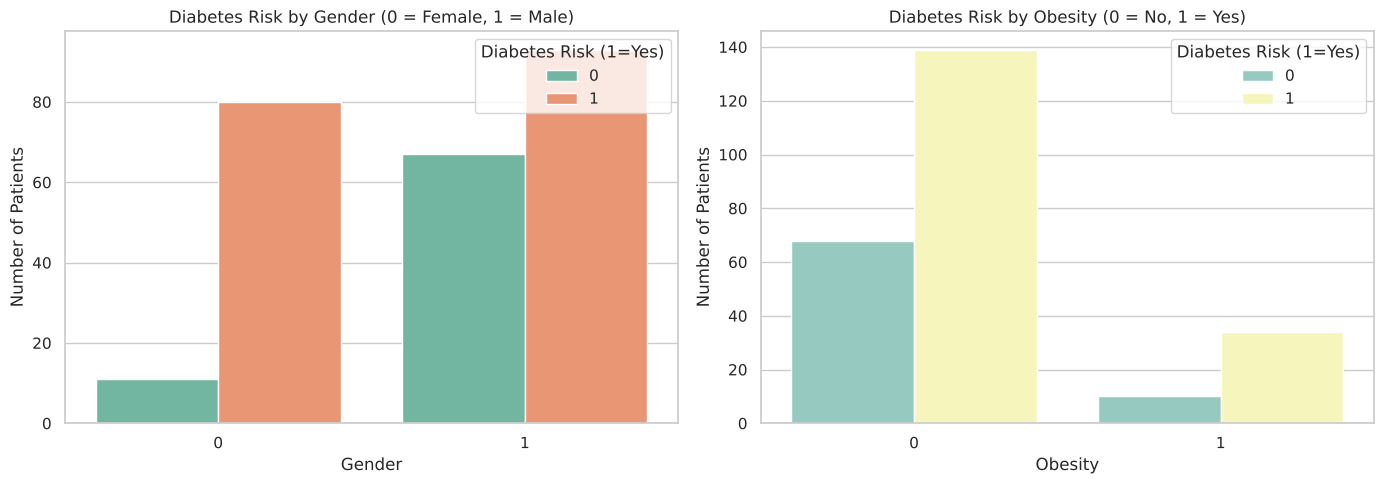

In [11]:
print("Visualizing gender and obesity")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# plot Gender
sns.countplot(ax=axes[0], data=df, x='Gender', hue='class', palette='Set2')
axes[0].set_title("Diabetes Risk by Gender (0 = Female, 1 = Male)", fontsize=12)
axes[0].set_ylabel("Number of Patients")
axes[0].legend(title='Diabetes Risk (1=Yes)', loc='upper right')

# Plot Obesity
sns.countplot(ax=axes[1], data=df, x='Obesity', hue='class', palette='Set3')
axes[1].set_title("Diabetes Risk by Obesity (0 = No, 1 = Yes)", fontsize=12)
axes[1].set_ylabel("Number of Patients")
axes[1].legend(title='Diabetes Risk (1=Yes)', loc='upper right')

plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
print("Splitting& Scaling")
# Separate the Medical Features (X) from the Target Risk (y)
X = df.drop(columns=['class'])
y = df['class']
# Split the data (80% for training, 20% for the final test)
# stratify=y is critical here: it ensures the 80/20 split has the exact same 
# percentage of diabetic patients as the original dataset.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  
)

# Scale the Data
# We fit the scaler only on the training data to prevent data leakage,
# then we transform both the train and test sets.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Data Ready: {X_train_scaled.shape[0]} patients, {X_train_scaled.shape[1]} features")
print(f"Testing Data Ready: {X_test_scaled.shape[0]} patients, {X_test_scaled.shape[1]} features")

Splitting& Scaling
Training Data Ready: 200 patients, 16 features
Testing Data Ready: 51 patients, 16 features


Full Correlation heatmap


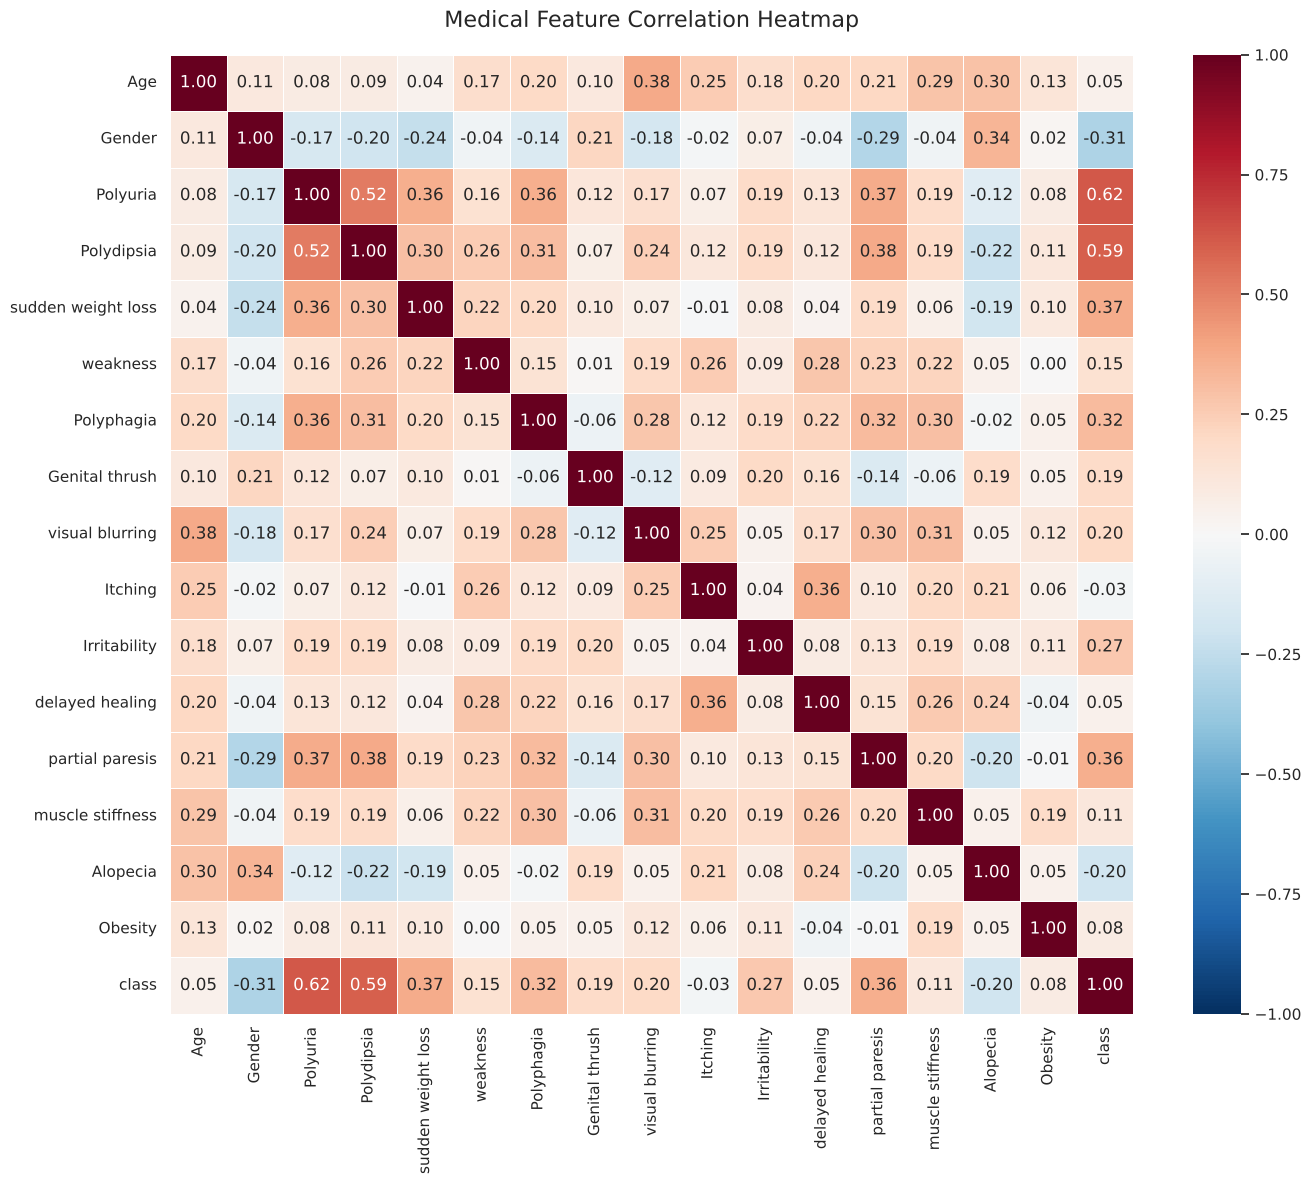

In [13]:
print("Full Correlation heatmap")
plt.figure(figsize=(14, 12))
# Calculate the correlation of every column against every other column
full_corr = df.corr()
# Draw a massive heatmap. 
# We use fmt=".2f" to keep it to two decimal places so it's readable.
sns.heatmap(full_corr, annot=True, cmap='RdBu_r', fmt=".2f", 
            linewidths=0.5, vmin=-1, vmax=1)

plt.title("Medical Feature Correlation Heatmap", fontsize=16, pad=20)
plt.tight_layout()
plt.show()

Total symptom burden vs. risk


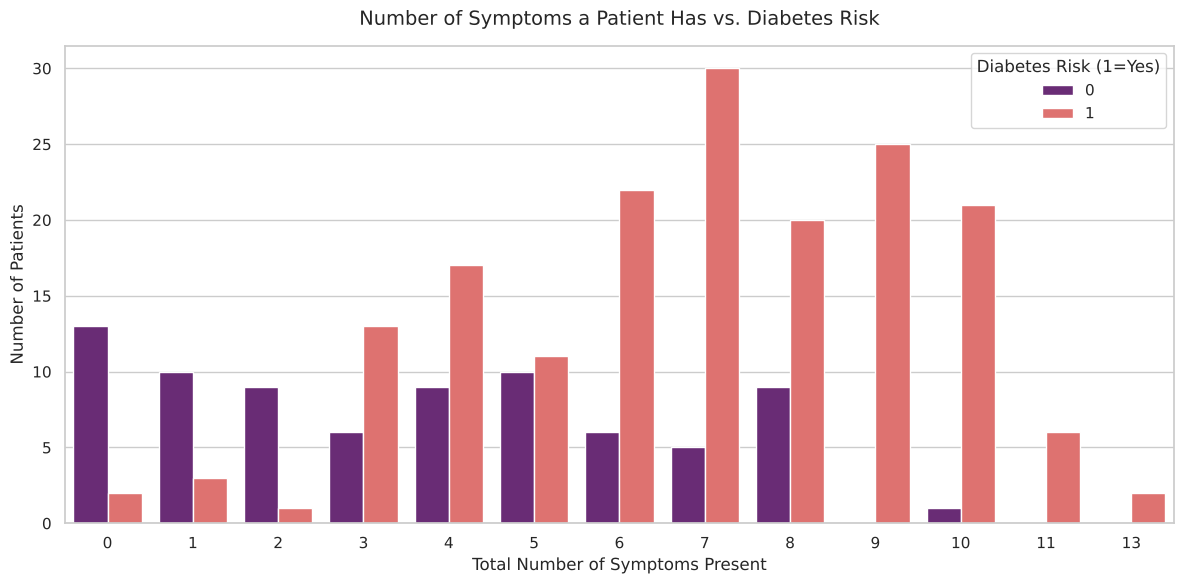

In [14]:
print("Total symptom burden vs. risk")
# Create a temporary copy so we don't permanently alter our ML dataset
temp_df = df.copy()

# List of all symptom columns (ignoring Age, Gender, and class)
symptom_cols = temp_df.columns.drop(['Age', 'Gender', 'class'])

# Add up all the 1s and 0s across the row for each patient
temp_df['Total_Symptoms'] = temp_df[symptom_cols].sum(axis=1)

plt.figure(figsize=(12, 6))
ax = sns.countplot(data=temp_df, x='Total_Symptoms', hue='class', palette='magma')

plt.title("Number of Symptoms a Patient Has vs. Diabetes Risk", fontsize=14, pad=15)
plt.xlabel("Total Number of Symptoms Present", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
ax.legend(title='Diabetes Risk (1=Yes)', loc='upper right')

plt.tight_layout()
plt.show()

age and gender prediction


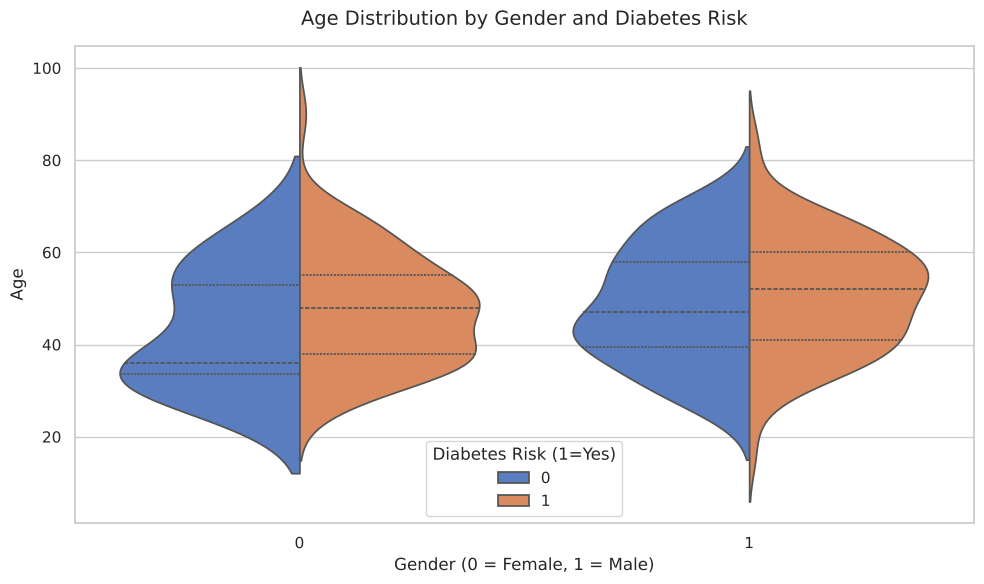

In [15]:
print("age and gender prediction")
plt.figure(figsize=(10, 6))
# split=True cuts the violin in half so we can compare healthy vs diabetic side-by-side
sns.violinplot(data=df, x='Gender', y='Age', hue='class', 
               split=True, palette='muted', inner='quartile')
plt.title("Age Distribution by Gender and Diabetes Risk", fontsize=14, pad=15)
plt.xlabel("Gender (0 = Female, 1 = Male)", fontsize=12)
plt.ylabel("Age", fontsize=12)
# Customizing the legend to be readable
plt.legend(title='Diabetes Risk (1=Yes)', loc='lower center')

plt.tight_layout()
plt.show()

In [16]:
# model training and evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# X_train_scaled, X_test_scaled, y_train and y_test come from the split cell above.
# Scaling is not needed for a Random Forest, it is kept so other models can be swapped in.
print("Model training")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

start_time = time.time()
rf_model.fit(X_train_scaled, y_train)
end_time = time.time()
print(f"Model trained in {round(end_time - start_time, 2)} seconds!\n")

Model training
Model trained in 0.17 seconds!



In [17]:
print("Evaluating the model")
# Make predictions and evaluate
y_pred = rf_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {accuracy * 100:.2f}%\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'Diabetic Risk (1)']))

Evaluating the model


Overall Accuracy: 92.16%

Detailed Classification Report:
                   precision    recall  f1-score   support

      Healthy (0)       0.80      1.00      0.89        16
Diabetic Risk (1)       1.00      0.89      0.94        35

         accuracy                           0.92        51
        macro avg       0.90      0.94      0.91        51
     weighted avg       0.94      0.92      0.92        51



Confusion matrix


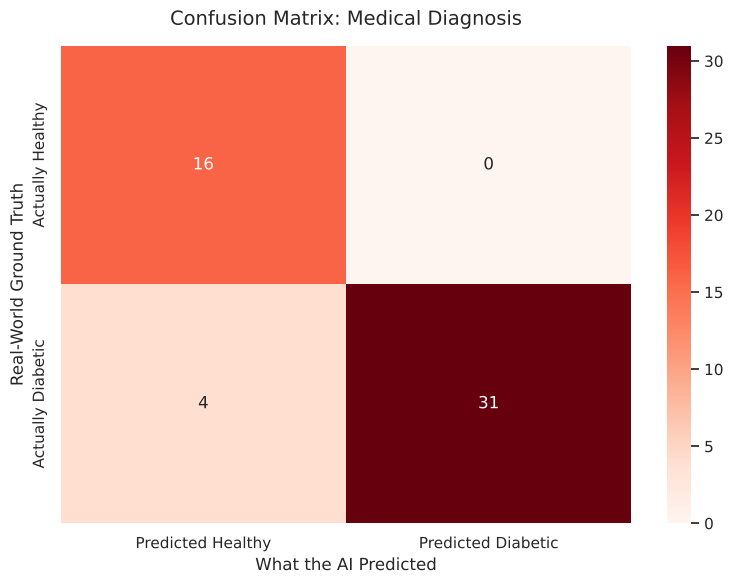

In [18]:
# confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Confusion matrix")
# Generate the matrix
cm = confusion_matrix(y_test, y_pred)
# Plot the matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['Predicted Healthy', 'Predicted Diabetic'], 
            yticklabels=['Actually Healthy', 'Actually Diabetic'])

plt.title("Confusion Matrix: Medical Diagnosis", fontsize=14, pad=15)
plt.ylabel("Real-World Ground Truth", fontsize=12)
plt.xlabel("What the AI Predicted", fontsize=12)

plt.tight_layout()
plt.show()

In [19]:
# Cross-validation
# The test set is small, so one split can be lucky or unlucky. 5-fold cross-validation
# gives a more honest picture. The scaler sits inside the pipeline so it is fitted on
# training folds only.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(),
                     RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
scores = cross_validate(pipe, X, y, cv=cv,
                        scoring=['accuracy', 'precision', 'recall', 'f1'])

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    vals = scores[f'test_{metric}']
    print(f"{metric.capitalize():10s}: {vals.mean():.3f} +/- {vals.std():.3f}")

Accuracy  : 0.936 +/- 0.019
Precision : 0.955 +/- 0.033
Recall    : 0.954 +/- 0.029
F1        : 0.954 +/- 0.013


Extracting feature importance


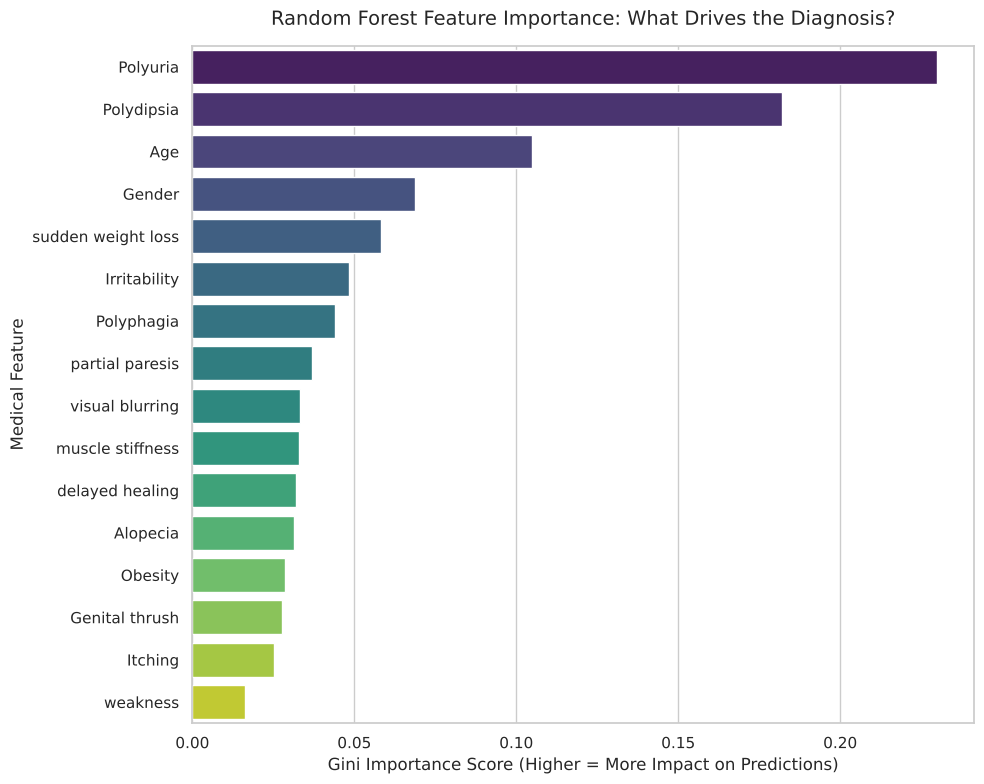

In [20]:
# feature importance
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
print("Extracting feature importance")

# Extract the importance scores from the trained model
importance_scores = rf_model.feature_importances_

# Match the scores to the names of the medical columns
# We use X.columns because X contains all the features we trained on
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance_scores
})

# Sort the dataframe from most important to least important
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot the results
plt.figure(figsize=(10, 8))
# Using a seaborn barplot to visualize the ranking
sns.barplot(
    data=feature_importance_df, 
    x='Importance', 
    y='Feature', 
    hue='Feature', 
    palette='viridis', 
    legend=False
)

plt.title("Random Forest Feature Importance: What Drives the Diagnosis?", fontsize=14, pad=15)
plt.xlabel("Gini Importance Score (Higher = More Impact on Predictions)", fontsize=12)
plt.ylabel("Medical Feature", fontsize=12)

plt.tight_layout()
plt.show()

Tuning Random Forest
Testing parameter combinations...


Best Parameters Found: {'class_weight': {0: 1, 1: 5}, 'max_depth': None, 'n_estimators': 200}

Optimized Classification Report:
                   precision    recall  f1-score   support

      Healthy (0)       0.85      0.69      0.76        16
Diabetic Risk (1)       0.87      0.94      0.90        35

         accuracy                           0.86        51
        macro avg       0.86      0.82      0.83        51
     weighted avg       0.86      0.86      0.86        51



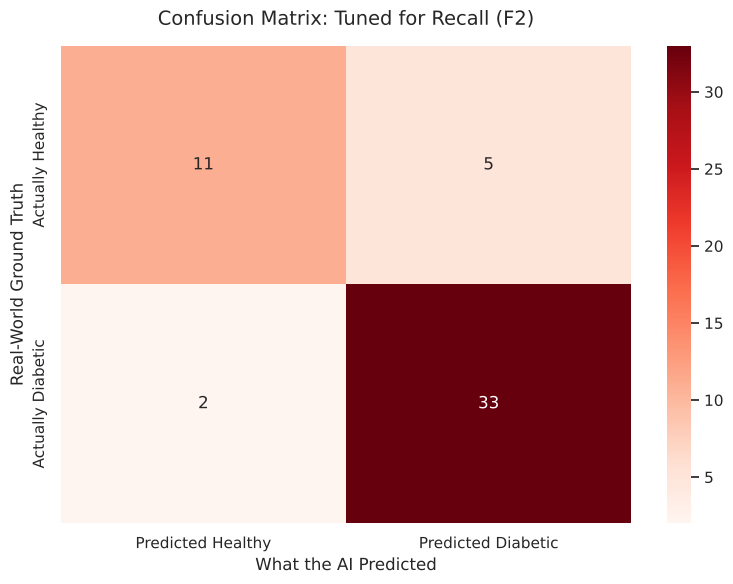

In [21]:
# model tuning
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, fbeta_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Tuning Random Forest")

# 1. Define the hyperparameter grid
# class_weight {0: 1, 1: 3} means the model is penalised 3 times as much for missing a
# diabetic patient as for wrongly flagging a healthy one.
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'class_weight': ['balanced', {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 5}]
}

# 2. Scoring: F2 weights recall higher than precision, so missing a diabetic patient
# costs more. Pure recall is not used because a model that labels everyone diabetic
# would score a perfect recall.
f2_scorer = make_scorer(fbeta_score, beta=2)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=5,
    n_jobs=-1
)

# 3. Run the search
print("Testing parameter combinations...")
grid_search.fit(X_train_scaled, y_train)

# 4. Extract the winning model
best_recall_model = grid_search.best_estimator_
print(f"Best Parameters Found: {grid_search.best_params_}\n")

# 5. Evaluate on the untouched test set
y_pred_recall = best_recall_model.predict(X_test_scaled)

print("Optimized Classification Report:")
print(classification_report(y_test, y_pred_recall, target_names=['Healthy (0)', 'Diabetic Risk (1)']))

# 6. Confusion matrix: compare the False Negatives with the first model
cm_recall = confusion_matrix(y_test, y_pred_recall)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_recall, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Healthy', 'Predicted Diabetic'],
            yticklabels=['Actually Healthy', 'Actually Diabetic'])

plt.title("Confusion Matrix: Tuned for Recall (F2)", fontsize=14, pad=15)
plt.ylabel("Real-World Ground Truth", fontsize=12)
plt.xlabel("What the AI Predicted", fontsize=12)

plt.tight_layout()
plt.show()